<a href="https://colab.research.google.com/github/ckurtz/teaching_UPC_UFRMI/blob/main/selfsupervised_demos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# References

[Course Webpage](https://sites.google.com/view/berkeley-cs294-158-sp20/home)

[1] Pathak, Deepak, et al. "Context encoders: Feature learning by inpainting." Proceedings of the IEEE conference on computer vision and pattern recognition. 2016.

[2] Gidaris, Spyros, Praveer Singh, and Nikos Komodakis. "Unsupervised representation learning by predicting image rotations." arXiv preprint arXiv:1803.07728 (2018).

[3] Chen, Ting, et al. "A simple framework for contrastive learning of visual representations." arXiv preprint arXiv:2002.05709 (2020).

[4] Noroozi, Mehdi, and Paolo Favaro. "Unsupervised learning of visual representations by solving jigsaw puzzles." European Conference on Computer Vision. Springer, Cham, 2016.

[5] Wang, Xiaolong, Allan Jabri, and Alexei A. Efros. "Learning correspondence from the cycle-consistency of time." Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition. 2019.

[6] Oord, Aaron van den, Yazhe Li, and Oriol Vinyals. "Representation learning with contrastive predictive coding." arXiv preprint arXiv:1807.03748 (2018).

[7] Hénaff, Olivier J., et al. "Data-efficient image recognition with contrastive predictive coding." arXiv preprint arXiv:1905.09272 (2019).

[8] Tian, Yonglong, Dilip Krishnan, and Phillip Isola. "Contrastive multiview coding." arXiv preprint arXiv:1906.05849 (2019).

[9] He, Kaiming, et al. "Momentum contrast for unsupervised visual representation learning." arXiv preprint arXiv:1911.05722 (2019).

[10] Doersch, Carl, Abhinav Gupta, and Alexei A. Efros. "Unsupervised visual representation learning by context prediction." Proceedings of the IEEE International Conference on Computer Vision. 2015.

[11] Ronneberger, Olaf, Philipp Fischer, and Thomas Brox. "U-net: Convolutional networks for biomedical image segmentation." International Conference on Medical image computing and computer-assisted intervention. Springer, Cham, 2015.

# Getting Started
Go to **Runtime -> Change runtime type** and make sure **Hardward accelerator** is set to **GPU**

In [ ]:
!if [ -d cs294-158-ssl ]; then rm -Rf cs294-158-ssl; fi
!git clone https://github.com/ckurtz/cs294-158-ssl
!pip install cs294-158-ssl/

import os
os.chdir('cs294-158-ssl')

Cloning into 'cs294-158-ssl'...
remote: Enumerating objects: 615, done.
remote: Counting objects: 100% (98/98), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 615 (delta 92), reused 90 (delta 90), pack-reused 517 (from 1)
Receiving objects: 100% (615/615), 3.10 MiB | 8.06 MiB/s, done.
Resolving deltas: 100% (442/442), done.
Processing ./cs294-158-ssl
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for deepul_helper: filename=deepul_helper-0.1.0-py3-none-any.whl size=25330 sha256=47d88790db86506612b6c7b81c0f6c25b3758e870352d84c3a7d3b17c4679def
  Stored in directory: /tmp/pip-ephem-wheel-cache-3n6fxsj4/wheels/41/c6/8a/07e8f4374eeb04ae58407716e4acc5040e23fe93acd34d166b
Successfully built deepul_helper


Run the cells below to download the necessary pretrained models. It should take a few minutes.

In [ ]:
!wget https://camille-kurtz.com/teaching/data.zip
!unzip -qq data.zip
!rm data.zip

--2026-10-29 15:57:10--  https://camille-kurtz.com/teaching/data.zip
Resolving camille-kurtz.com (camille-kurtz.com)... 213.186.33.3
Connecting to camille-kurtz.com (camille-kurtz.com)|213.186.33.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4227668031 (3.9G) [application/zip]
Saving to: ‘data.zip’

data.zip            100%[===================>]   3.94G  15.9MB/s    in 4m 57s  

2026-10-29 16:02:08 (13.6 MB/s) - ‘data.zip’ saved [4227668031/4227668031]



In [ ]:
!wget https://camille-kurtz.com/teaching/results.zip
!unzip -qq results.zip
!rm results.zip

--2026-10-29 16:02:57--  https://camille-kurtz.com/teaching/results.zip
Resolving camille-kurtz.com (camille-kurtz.com)... 213.186.33.3
Connecting to camille-kurtz.com (camille-kurtz.com)|213.186.33.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2636425194 (2.5G) [application/zip]
Saving to: ‘results.zip’

results.zip         100%[===================>]   2.46G  28.3MB/s    in 3m 5s   

2026-10-29 16:06:03 (13.6 MB/s) - ‘results.zip’ saved [2636425194/2636425194]



The models and demos shown were pre-trained. The code used for all the demos can be found in the github repo [here](https://github.com/wilson1yan/cs294-158-ssl). Follow the README to train models on CIFAR10 or ImageNet.

# Self-Supervised Learning Tasks
Self-supervised learning is a rapidly growing field, its success largely accelerated by growing compute and the vast amount of unlabeled data available for training. The hope is that by pretraining on specially designed self-supervised tasks, the models would be able to learn semantically meaningful representations to be used for downstream tasks. In the following demos, we will look at a few examples of these self-supervised tasks.

In [ ]:
from deepul_helper.demos import load_model_and_data, evaluate_accuracy, display_nearest_neighbors, show_context_encoder_inpainting

%matplotlib inline

## Demo 1: Context Encoder [[1]](https://arxiv.org/abs/1604.07379)

The context encoder structures its self-supervised learning task by inpainting masked images. For example, the figure below shows different masking shapes, such as center masking, random block masking, and segmentation masking. Note that segmentation masking (c) is not purely self-supervised since we would need to train a image segmentation model which requires labels. However, the other two masking schemes (a) and (b) and purely self-supervised.

![](https://drive.google.com/uc?id=1fhzkULYTtyMGUUF2n9dlPayJSdcY5pRv)

More formally, the context encoder optimizes the following reconstruction loss:
$$\mathcal{L}_{rec} = \left\Vert \hat{M} \odot (x - F((1 - \hat{M})\odot x)) \right\Vert^2_2$$
where $\hat{M}$ is the masked region, $x$ is the image, and $F$ is the context encoder that tries to reconstruct the masked portion. In addition to the reconstruction loss, the paper introduces an adversarial loss that encourages more realistic inpaintings.
$$L_{adv} = \max_D \mathbb{E}_{x\in \chi} [\log(D(x)) + \log(1 - D(F((1-\hat{M})\odot x)))]$$
However, this demo does not use the adversarial portion of the loss.

### Example Code

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ContextEncoder(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes):
        super().__init__()
        input_channels = 3

        self.latent_dim = 4000

        # Encodes the masked image
        self.encoder = nn.Sequential(
            # 128 x 128 Input
            nn.Conv2d(input_channels, 64, 4, stride=2, padding=1), # 64 x 64
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 64, 4, stride=2, padding=1), # 32 x 32
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, stride=2, padding=1), # 16 x 16
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, stride=2, padding=1), # 8 x 8
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, 4, stride=2, padding=1), # 4 x 4
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, self.latent_dim, 4) # 1 x 1
        )

        # Only reconstructs the masked part of the image and not the whole image
        self.decoder = nn.Sequential(
           nn.BatchNorm2d(self.latent_dim),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(self.latent_dim, 512, 4, stride=1, padding=0), # 4 x 4
           nn.BatchNorm2d(512),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(512, 256, 4, stride=2, padding=1), # 8 x 8
           nn.BatchNorm2d(256),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), # 16 x 16
           nn.BatchNorm2d(128),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), # 32 x 32
           nn.BatchNorm2d(64),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(64, input_channels, 4, stride=2, padding=1), # 64 x 64
           nn.Tanh()
        )

        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        classifier = nn.Sequential(
            nn.Flatten(),
            nn.BatchNorm1d(self.latent_dim, affine=False),
            nn.Linear(self.latent_dim, self.n_classes)
        )
        return classifier

    def forward(self, images):
        # Extract a 64 x 64 center from 128 x 128 image
        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()
        # Mask out a 64 x 64 center with slight overlap
        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        return dict(Loss=F.mse_loss(center_recon, images_center)), torch.flatten(z, 1)

    def encode(self, images):
        images_masked = images
        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0
        return self.encoder(images_masked)

    def reconstruct(self, images):
        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()
        images_masked[:, 0, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        images_recon = images_masked.clone()
        images_recon[:, :, 32:32+64, 32:32+64] = center_recon
        return images_masked, images_recon


### Inpainting Examples
For each pair of images, the left image is the masked input and the right the inpainted reconstruction.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


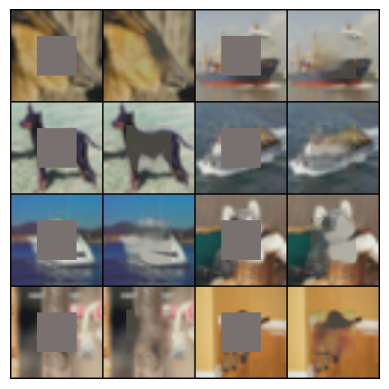

In [ ]:
show_context_encoder_inpainting()

### Linear Classification
By design the model architecture is an encoder -> decoder module. We can use the bottleneck layer as our learned representation. Below, we show linear classification accuracy results on CIFAR10 using the learned representations.

In [ ]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('context_encoder')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Train Set
Top 1 Accuracy: 53.236, Top 5 Accuracy: 94.094

Test Set
Top 1 Accuracy: 45.77, Top 5 Accuracy: 90.29



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


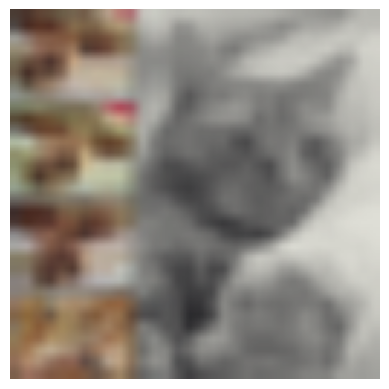

Top 16 Nearest Neighbors (in latent space)


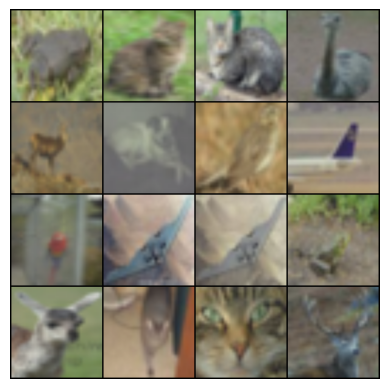

Image 2


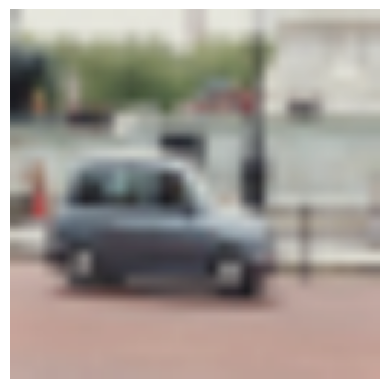

Top 16 Nearest Neighbors (in latent space)


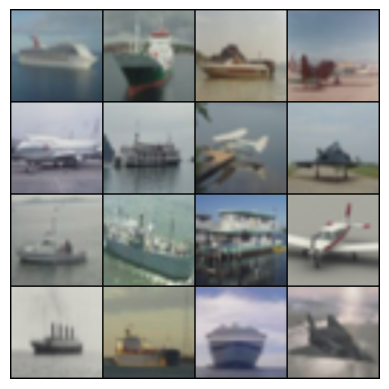

Image 3


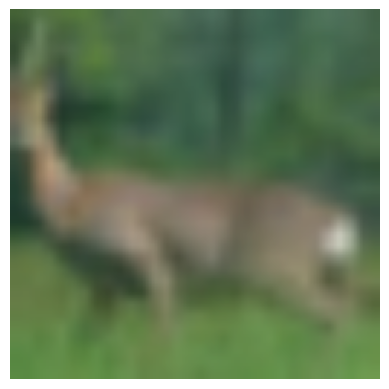

Top 16 Nearest Neighbors (in latent space)


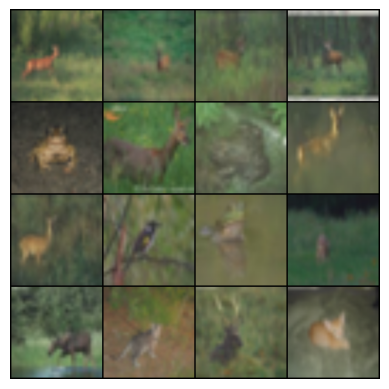

Image 4


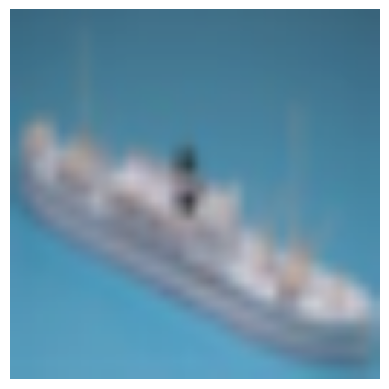

Top 16 Nearest Neighbors (in latent space)


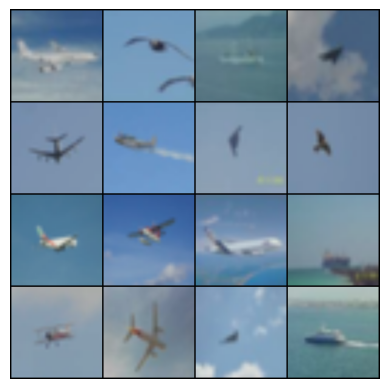

In [ ]:
display_nearest_neighbors('context_encoder', model, test_loader)

## Demo 2: Rotation Prediction [[2]](https://arxiv.org/abs/1803.07728)

In this paper, the authors show that accurately predicting the degrees of rotation in images is a self-supervised learning task that learns good representations for downstream tasks.

![](https://drive.google.com/uc?id=1eHXLH-N_6uMGRzdf1Wjnga26qlS5-FRv)

More specifically, the authors showed that training a common CNN architecture (AlexNet, ResNet) on the rotation task learns semantically interpretable convolutional masks similar to those learned in supervised learning.

### Example Code

In [ ]:
import math

import torch
import torch.nn as nn
import torch.nn.functional as F


class RotationPrediction(nn.Module):
    metrics = ['Loss', 'Acc1']
    metrics_fmt = [':.4e', ':6.2f']

    def __init__(self, dataset, n_classes):
        super().__init__()
        if dataset == 'cifar10':
            self.model = NetworkInNetwork()
            self.latent_dim = 192 * 8 * 8
            self.feat_layer = 'conv2'
        elif 'imagenet' in dataset:
            self.model = AlexNet()
            self.latent_dim = 256 * 13 * 13
            self.feat_layer = 'conv5'
        else:
            raise Exception('Unsupported dataset:', dataset)
        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        if self.dataset == 'cifar10':
            classifier = nn.Sequential(
                Flatten(),
                nn.BatchNorm1d(self.latent_dim, affine=False),
                nn.Linear(self.latent_dim, self.n_classes)
            )
        elif 'imagenet' in self.dataset:
            classifier = nn.Sequential(
                nn.AdaptiveMaxPool2d((6, 6)),
                nn.BatchNorm2d(256, affine=False),
                Flatten(),
                nn.Linear(256 * 6 * 6, self.n_classes)
            )
        else:
            raise Exception('Unsupported dataset:', dataset)
        return classifier

    def forward(self, images):
        batch_size = images.shape[0]
        images, targets = self._preprocess(images)
        targets = targets.to(images.get_device())

        logits, zs = self.model(images, out_feat_keys=('classifier', self.feat_layer))
        loss = F.cross_entropy(logits, targets)

        pred = logits.argmax(dim=-1)
        correct = pred.eq(targets).float().sum()
        acc = correct / targets.shape[0] * 100.

        return dict(Loss=loss, Acc1=acc), zs[:batch_size]

    def encode(self, images):
        zs = self.model(images, out_feat_keys=(self.feat_layer,))
        return zs

    def _preprocess(self, images):
        batch_size = images.shape[0]
        images_90 = torch.flip(images.transpose(2, 3), (2,))
        images_180 = torch.flip(images, (2, 3))
        images_270 = torch.flip(images, (2,)).transpose(2, 3)
        images_batch = torch.cat((images, images_90, images_180, images_270), dim=0)
        targets = torch.arange(4).long().repeat(batch_size)
        targets = targets.view(batch_size, 4).transpose(0, 1)
        targets = targets.contiguous().view(-1)
        return images_batch, targets

### Linear Classification
We can use the feature maps in the later convolutional layers of the pretrained model as our learned representation for linear classification.

In [ ]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('rotation')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Train Set
Top 1 Accuracy: 79.49, Top 5 Accuracy: 99.146

Test Set
Top 1 Accuracy: 79.91, Top 5 Accuracy: 99.12



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


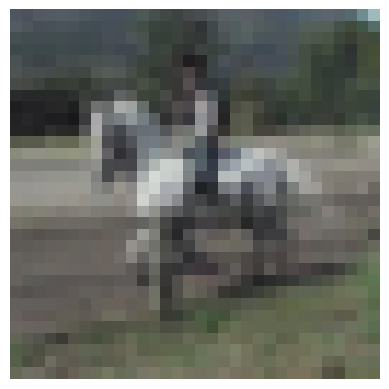

Top 16 Nearest Neighbors (in latent space)


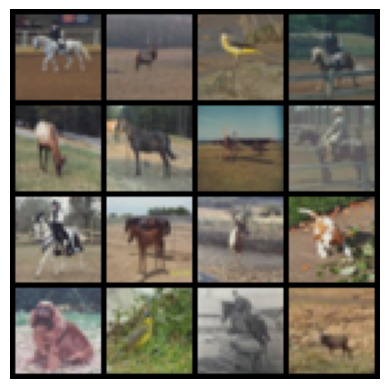

Image 2


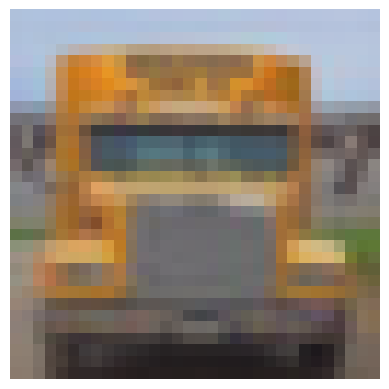

Top 16 Nearest Neighbors (in latent space)


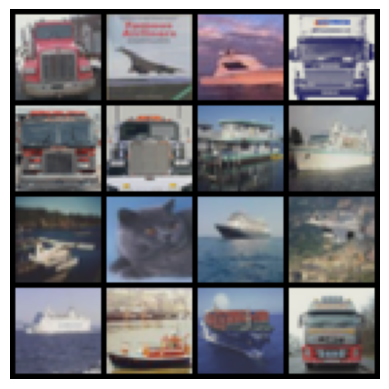

Image 3


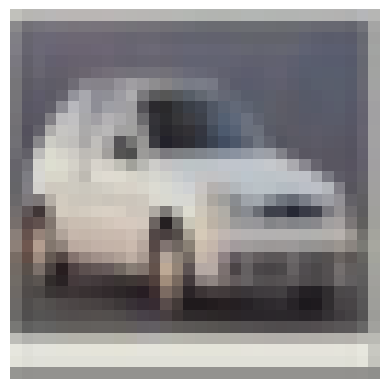

Top 16 Nearest Neighbors (in latent space)


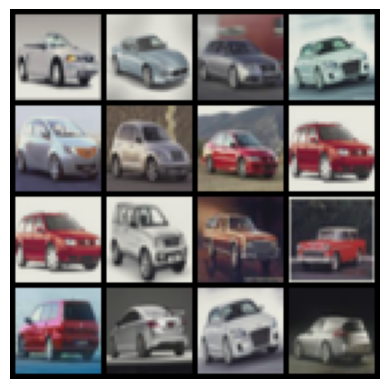

Image 4


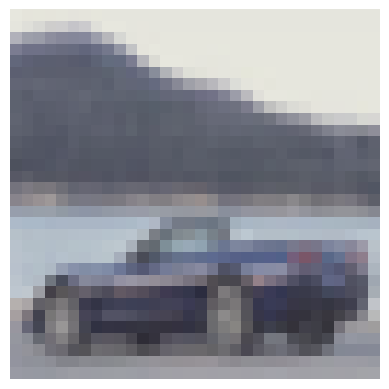

Top 16 Nearest Neighbors (in latent space)


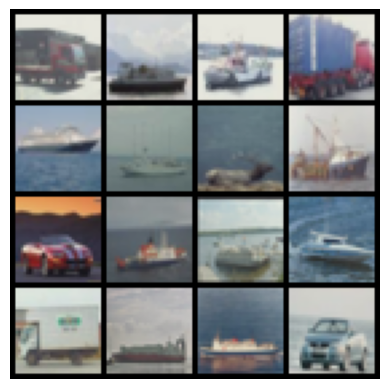

In [ ]:
display_nearest_neighbors('rotation', model, test_loader)

## Demo 3: SimCLR [[3]](https://arxiv.org/abs/2002.05709)

SimCLR is a contrastive learning framework to learn strong visual representations. An image $x$ is processed using data augmentation to produce two variants $x_i$ and $x_j$ which are both fed into encoder $f$ (a CNN) and projection head $g$ (a small MLP). The models optimize a contrastive loss to maximally align projected latents $z_i, z_j$. We consider $x_i, x_j$ as a positive pair, and any other $x_i, x_k$ pairs (i.e. different images in the same batch) are negative pairs. A visual diagram of the training procedure is shown below (from the paper).

![](https://drive.google.com/uc?id=1XW1uIkUTMSa0DZncivSYXzM5gA5FIhF6)

More formally, the loss between positive example $z_i, z_j$ is:
$$\ell_{i,j} = -\log{\frac{\exp(\text{sim}(z_i, z_j)/\tau)}{\sum_{k=1}^{2N}\mathbb{1}_{[k\neq i]}\exp(\text{sim}(z_i, z_k)/\tau)}}$$
where $\text{sim}(z_i, z_j) = z_i^Tz_j / (\left\Vert z_i \right\Vert \left\Vert z_j \right\Vert)$. The loss function can also be interpreted as a standard cross entropy loss to classify positive samples where logits are constructed using a given similarity function.

Note: A common idea in contrastive learning methods is that a larger batch means more negative samples. Therefore, these methods usually benefit the most from large-batch learning compared to other self-supervised learning tasks.

### Example Code

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from deepul_helper.resnet import resnet_v1
from deepul_helper.batch_norm import SyncBatchNorm, BatchNorm1d

# Some code adapted from https://github.com/sthalles/SimCLR
class SimCLR(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes, dist=None):
        super().__init__()
        self.temperature = 0.5
        self.projection_dim = 128

        if dataset == 'cifar10':
            resnet = resnet_v1((3, 32, 32), 50, 1, cifar_stem=True)
            resnet = SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048
        elif 'imagenet' in dataset:
            resnet = resnet_v1((3, 128, 128), 50, 1, cifar_stem=False)
            if dist is not None:
                resnet = nn.SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048

        self.proj = nn.Sequential(
            nn.Linear(self.latent_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim),
            nn.ReLU(inplace=True),
            nn.Linear(self.projection_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim, center=False)
        )

        self.dataset = dataset
        self.n_classes = n_classes
        self.dist = dist

    def construct_classifier(self):
        return nn.Sequential(nn.Linear(self.latent_dim, self.n_classes))

    def forward(self, images):
        n = images[0].shape[0]
        xi, xj = images
        hi, hj = self.encode(xi), self.encode(xj) # (N, latent_dim)
        zi, zj = self.proj(hi), self.proj(hj) # (N, projection_dim)
        zi, zj = F.normalize(zi), F.normalize(zj)

        # Each training example has 2N - 2 negative samples
        # 2N total samples, but exclude the current and positive sample

        if self.dist is None:
            zis = [zi]
            zjs = [zj]
        else:
            zis = [torch.zeros_like(zi) for _ in range(self.dist.get_world_size())]
            zjs = [torch.zeros_like(zj) for _ in range(self.dist.get_world_size())]

            self.dist.all_gather(zis, zi)
            self.dist.all_gather(zjs, zj)

        z1 = torch.cat((zi, zj), dim=0) # (2N, projection_dim)
        z2 = torch.cat(zis + zjs, dim=0) # (2N * n_gpus, projection_dim)

        sim_matrix = torch.mm(z1, z2.t()) # (2N, 2N * n_gpus)
        sim_matrix = sim_matrix / self.temperature
        # Mask out same-sample terms
        n_gpus = 1 if self.dist is None else self.dist.get_world_size()
        rank = 0 if self.dist is None else self.dist.get_rank()
        sim_matrix[torch.arange(n), torch.arange(rank*n, (rank+1)*n)]  = -float('inf')
        sim_matrix[torch.arange(n, 2*n), torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n)] = -float('inf')

        targets = torch.cat((torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n),
                             torch.arange(rank*n, (rank+1)*n)), dim=0)
        targets = targets.to(sim_matrix.get_device()).long()

        loss = F.cross_entropy(sim_matrix, targets, reduction='sum')
        loss = loss / n
        return dict(Loss=loss), hi

    def encode(self, images):
        return self.resnet(images[0])

    def get_features(self, images):
        return self.resnet.get_features(images)


### Linear Classification
We can use the encoded vector $h_i$ as our latent representation.

In [ ]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('simclr')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Train Set
Top 1 Accuracy: 90.036, Top 5 Accuracy: 99.506

Test Set
Top 1 Accuracy: 92.84, Top 5 Accuracy: 99.86



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


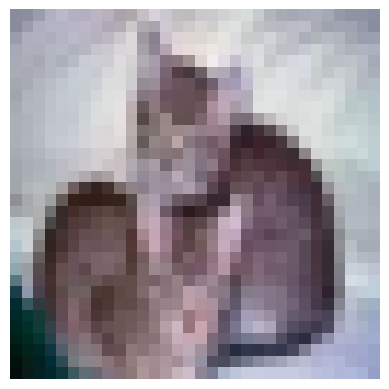

Top 16 Nearest Neighbors (in latent space)


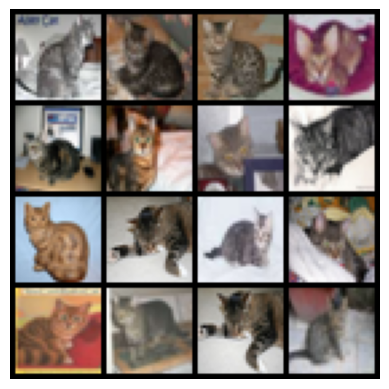

Image 2


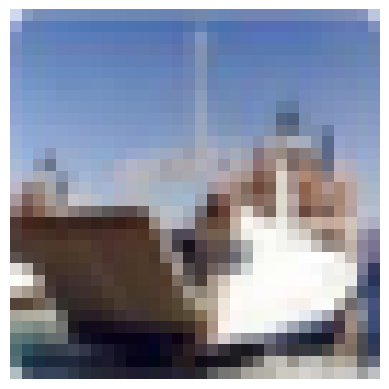

Top 16 Nearest Neighbors (in latent space)


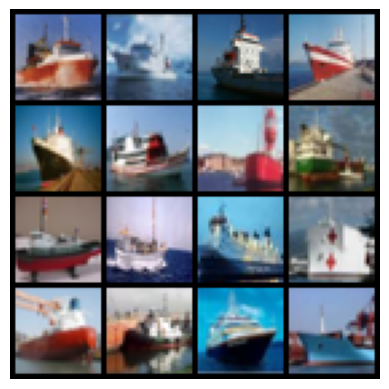

Image 3


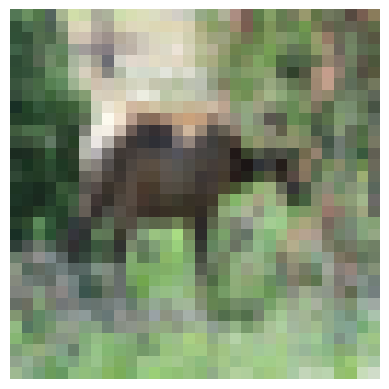

Top 16 Nearest Neighbors (in latent space)


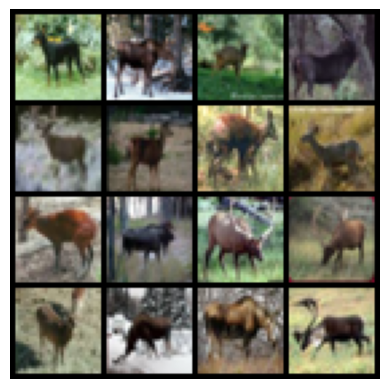

Image 4


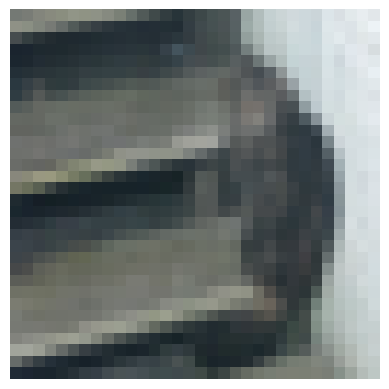

Top 16 Nearest Neighbors (in latent space)


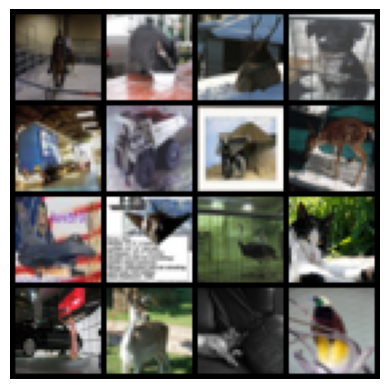

In [ ]:
display_nearest_neighbors('simclr', model, test_loader)

# TP :

## Consigne 3 :

Chargement et évaluation de : context_encoder


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Chargement et évaluation de : rotation
Chargement et évaluation de : simclr

Tableau comparatif des performances sur les données CIFAR10 :


,Modèles,Top-1 Train Accuracy (%),Top-1 Test Accuracy (%),Top-5 Train Accuracy (%),Top-5 Test Accuracy (%)
0,Context Encoder,53.236,45.77,94.094,90.29
1,Rotation,79.498,79.91,99.102,99.12
2,Simclr,90.194,92.84,99.506,99.86


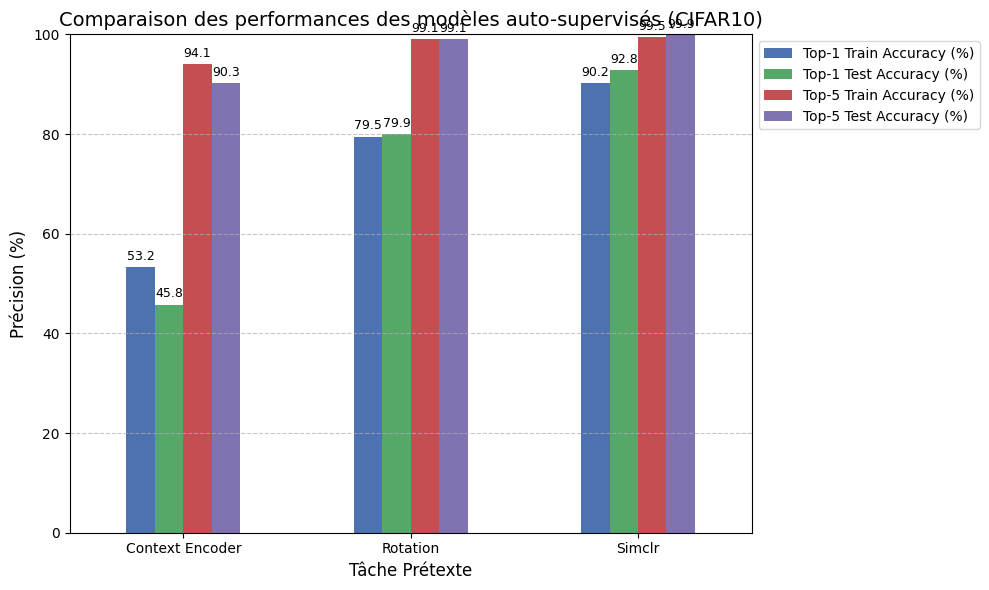

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from deepul_helper.demos import load_model_and_data, evaluate_classifier

# Liste contenant le nom des tâches prétextes qu'on va évaluer (on prend les 3 premières pour le tp)
model_names = ['context_encoder', 'rotation', 'simclr']
results = []

for name in model_names:
    print(f"Chargement et évaluation de : {name}")
    # Chargement du modèle, du classifieur linéaire et des données associées
    model, linear_classifier, train_loader, test_loader = load_model_and_data(name)

    # On évalue sur le train set et le test set
    train_acc1, train_acc5 = evaluate_classifier(model, linear_classifier, train_loader)
    test_acc1, test_acc5 = evaluate_classifier(model, linear_classifier, test_loader)

    # On extrait les valeurs des accuracies pour le Top-1 et le Top-5
    val_train1 = train_acc1.item() if hasattr(train_acc1, 'item') else train_acc1
    val_test1 = test_acc1.item() if hasattr(test_acc1, 'item') else test_acc1
    val_train5 = train_acc5.item() if hasattr(train_acc5, 'item') else train_acc5
    val_test5 = test_acc5.item() if hasattr(test_acc5, 'item') else test_acc5

    results.append({
        'Modèles': name.replace('_', ' ').title(),
        'Top-1 Train Accuracy (%)': val_train1,
        'Top-1 Test Accuracy (%)': val_test1,
        'Top-5 Train Accuracy (%)': val_train5,
        'Top-5 Test Accuracy (%)': val_test5
    })

# Crée le tableau récapitulatif
df_results = pd.DataFrame(results)

print("\nTableau comparatif des performances sur les données CIFAR10 :")
display(df_results)

# Création du graphique en barres
ax = df_results.plot(
    x='Modèles',
    y=[
        'Top-1 Train Accuracy (%)',
        'Top-1 Test Accuracy (%)',
        'Top-5 Train Accuracy (%)',
        'Top-5 Test Accuracy (%)'
    ],
    kind='bar',
    figsize=(10, 6),
    color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'] # Ajout de deux couleurs pour le Top-5
)

plt.title('Comparaison des performances des modèles auto-supervisés (CIFAR10)', fontsize=14)
plt.ylabel('Précision (%)', fontsize=12)
plt.xlabel('Tâche Prétexte', fontsize=12)
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1)) # Déplacement de la légende pour éviter de cacher les barres

# Ajout des valeurs exactes au-dessus de chaque barre
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

## Consigne 4 :

### Avec CIFAR100 :


--- Traitement de : Context Encoder ---


100%|██████████| 169M/169M [18:29<00:00, 152kB/s]
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Entraînement du classifieur linéaire (128x128)...
Époque 1/10 - Perte : 3.8763
Époque 2/10 - Perte : 3.3016
Époque 3/10 - Perte : 3.0464
Époque 4/10 - Perte : 2.8650
Époque 5/10 - Perte : 2.7102
Époque 6/10 - Perte : 2.5806
Époque 7/10 - Perte : 2.4742
Époque 8/10 - Perte : 2.3792
Époque 9/10 - Perte : 2.2918
Époque 10/10 - Perte : 2.2166
Évaluation en cours.

--- Traitement de : Rotation ---
Entraînement du classifieur linéaire (32x32)...
Époque 1/10 - Perte : 3.0014
Époque 2/10 - Perte : 1.0865
Époque 3/10 - Perte : 0.5451
Époque 4/10 - Perte : 0.3219
Époque 5/10 - Perte : 0.2453
Époque 6/10 - Perte : 0.2331
Époque 7/10 - Perte : 0.2623
Époque 8/10 - Perte : 0.2685
Époque 9/10 - Perte : 0.2440
Époque 10/10 - Perte : 0.2190
Évaluation en cours.

--- Traitement de : Simclr ---
Entraînement du classifieur linéaire (32x32)...
Époque 1/10 - Perte : 2.9991
Époque 2/10 - Perte : 2.2618
Époque 3/10 - Perte : 2.0542
Époque 4/10 - Perte : 1.9271
Époque 5/10 - Perte : 1.8370
Époque 6/10 - Perte

,Modèles,Top-1 Train Accuracy (%),Top-1 Test Accuracy (%),Top-5 Train Accuracy (%),Top-5 Test Accuracy (%)
0,Context Encoder,53.308,23.23,80.536,48.92
1,Rotation,96.486,48.79,99.914,76.19
2,Simclr,57.840,53.05,85.336,81.83


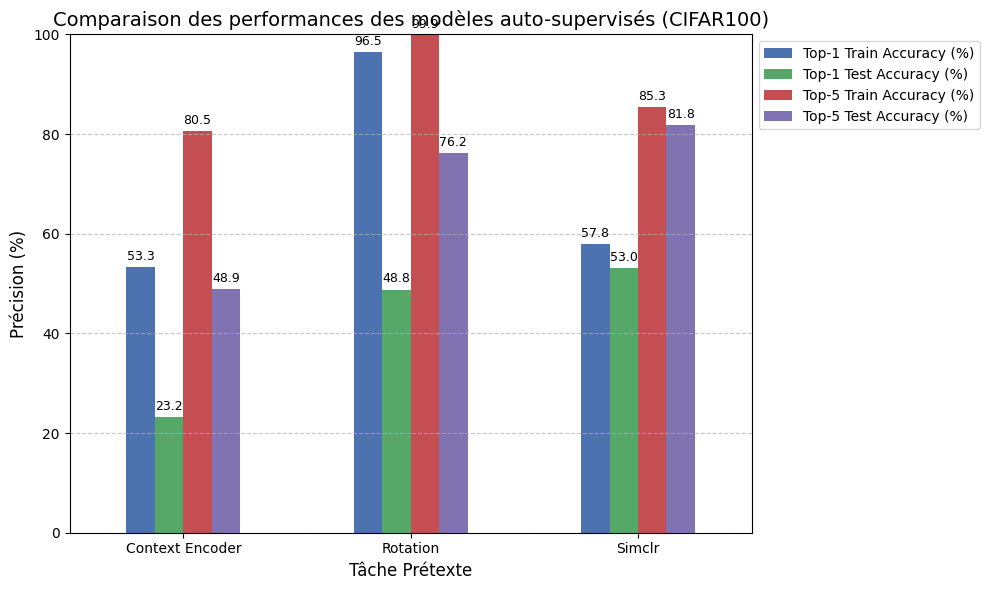

In [ ]:
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from deepul_helper.demos import load_model_and_data

# on utilise cette fonction car des problèmes ont été rencontrés lors de l'entraînement de SimCLR avec evaluate_classifier.
def compute_accuracy(model, classifier, dataloader, device):
    """Cette fonction évalue les performannces du modèle et de son classifieur
    linéaire sur un jeu de données. Renvoie un tuple contenant la précision top 1 et top 5.

    Args :
        model (nn.Module) : encodeur pré-entraîné (gelé dans notre cas) issu du self-supervised learning.
        classifier (nn.Module) : classifieur linéaire entraîné sur les reprséentation de l'encodeur.
        dataloader (DataLoader) : va charger les données pour l'évaluation.
        device (torch.device) : choix du périphérique de calcul (cuda ou cpu).
    """
    model.eval()
    classifier.eval()
    top1_correct = 0
    top5_correct = 0
    total = 0

    # On désactive le calcul des gradients pour accélérer l'avaluation et économiser de la mémoire.
    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)

            # Va extraire les carac via l'encodeur de base
            features = model.encode(images)
            outputs = classifier(features) # Prédit via la couche linéaire ajoutée

            # Calcul les précisions Top-1 et Top-5
            _, pred = outputs.topk(5, 1, True, True)
            pred = pred.t()
            correct = pred.eq(labels.view(1, -1).expand_as(pred)) # Compare avec les vraies étiquettes

            # Calcul les prédictions correctes pour le top 1 et 5.
            top1_correct += correct[:1].reshape(-1).float().sum(0).item()
            top5_correct += correct[:5].reshape(-1).float().sum(0).item()
            total += labels.size(0)

    # Renvoie les pourcentages de précision
    return (top1_correct / total) * 100, (top5_correct / total) * 100

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_names = ['context_encoder', 'rotation', 'simclr'] # Liste contenant les modèles à évaluer
results = []
epochs = 10
criterion = nn.CrossEntropyLoss()

for name in model_names:
    print(f"\n--- Traitement de : {name.replace('_', ' ').title()} ---")

    # Définit la taille d'image attendue par l'encodeur
    # 128x128 pour Context Encoder, 32x32 pour les autres
    img_size = 128 if name == 'context_encoder' else 32

    # Trnasforme les images
    transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    # Crée les DataLoaders CIFAR100 avec la bonne taille d'image selon le modèle
    train_dataset = torchvision.datasets.CIFAR100(root='./data', train=True, download=True, transform=transform)
    test_dataset = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)

    train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2)
    test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=2)

    # Chargement de l'encodeur pré-entraîné
    model, _, _, _ = load_model_and_data(name)
    model = model.to(device)

    # On gèle les poids de l'encodeur (pas de gradient calculé ou màj, ici)
    for param in model.parameters():
        param.requires_grad = False

    # Création et entraînement du nouveau classifieur linéaire pour les 100 classes de CIFAR100
    model.n_classes = 100
    linear_classifier = model.construct_classifier().to(device)
    optimizer = optim.Adam(linear_classifier.parameters(), lr=1e-3)

    model.eval()
    linear_classifier.train()

    print(f"Entraînement du classifieur linéaire ({img_size}x{img_size})...")
    for epoch in range(epochs):
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()

            # Passe les images dans l'encodeur gelé pour avoir les représentation
            with torch.no_grad():
                features = model.encode(images)

            # On entraîne juste la couche de classification linéaire
            outputs = linear_classifier(features)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        print(f"Époque {epoch+1}/{epochs} - Perte : {running_loss/len(train_loader):.4f}")

    # Évaluation sur les train et test sets.
    print("Évaluation en cours.")
    train_acc1, train_acc5 = compute_accuracy(model, linear_classifier, train_loader, device)
    test_acc1, test_acc5 = compute_accuracy(model, linear_classifier, test_loader, device)

    # On stocke les métrique d'évaluation
    results.append({
        'Modèles': name.replace('_', ' ').title(),
        'Top-1 Train Accuracy (%)': train_acc1,
        'Top-1 Test Accuracy (%)': test_acc1,
        'Top-5 Train Accuracy (%)': train_acc5,
        'Top-5 Test Accuracy (%)': test_acc5
    })

# Affichage des résultats (tableau et graphique)
df_results = pd.DataFrame(results)
print("\nTableau comparatif des performances sur les données CIFAR100 :")
display(df_results)

ax = df_results.plot(
    x='Modèles',
    y=[
        'Top-1 Train Accuracy (%)',
        'Top-1 Test Accuracy (%)',
        'Top-5 Train Accuracy (%)',
        'Top-5 Test Accuracy (%)'
    ],
    kind='bar',
    figsize=(10, 6),
    color=['#4C72B0', '#55A868', '#C44E52', '#8172B2']
)

plt.title('Comparaison des performances des modèles auto-supervisés (CIFAR100)', fontsize=14)
plt.ylabel('Précision (%)', fontsize=12)
plt.xlabel('Tâche Prétexte', fontsize=12)
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

## Consigne 5 :

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import random

class ContextPrediction(nn.Module):
    """
    Il s'agit là d'un modèle auto-supervisé aprrenant à prédire la position relative
    d'un patch par rapport à un patch requête central.
    """

    metrics = ['Loss', 'Accuracy']
    metrics_fmt = [':.4e', ':.2f']

    def __init__(self, dataset, n_classes):
        super().__init__()
        input_channels = 3
        self.latent_dim = 1024

        # Encodeur CNN partagé (attend des entrées de 32x32 pour en extraire les carac)
        self.encoder = nn.Sequential(
            nn.Conv2d(input_channels, 64, 4, stride=2, padding=1),   # Sortie 16x16
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),              # Sortie 8x8
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, stride=2, padding=1),             # Sortie 4x4
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, self.latent_dim, 4),                      # Sortie 1x1
            nn.AdaptiveAvgPool2d((1, 1)), # Sécurité pour garantir une sortie 1x1 indépendante de l'entrée
            nn.Flatten()
        )

        # MLP pour la tâche prétexte (identifie l'une des 8 positions spatiales possibles)
        self.pretext_classifier = nn.Sequential(
            nn.Linear(self.latent_dim * 2, 512), # On multiplie par 2 car on concatène 2 patchs : le centre et son voisin.
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 8)
        )

        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        """
        On construit classifieur linéaire pour effectuer l'évaluation en aval (linear probing).
        """

        classifier = nn.Sequential(
            nn.Flatten(),
            nn.BatchNorm1d(self.latent_dim, affine=False),
            nn.Linear(self.latent_dim, self.n_classes)
        )
        return classifier

    def extract_patches(self, images):
        """
        Cette fonction génère les paires de patchs (centre, voisin) ainsi que
        les étiquettes de positiion.
        """

        # Si l'image est trop petite, on l'agrandit en 128x128 pour pouvoir extraire des patchs 32x32 avec écart (gap)
        if images.size(2) < 96:
            images = F.interpolate(images, size=(128, 128), mode='bilinear', align_corners=False)

        batch_size, _, H, W = images.size()
        cell_size = H // 3        # 42 pixels pour une image 128x128
        patch_size = 32           # Taille fixe attendue par l'encodeur
        max_jitter = cell_size - patch_size # On ajoute 10 pixels de marge pour créer un gap et du jitter

        # On extrait le patch central (dans la cellule du milieu donc en (1, 1))
        offset_c = max_jitter // 2
        c_start = cell_size + offset_c
        center = images[:, :, c_start:c_start+patch_size, c_start:c_start+patch_size]

        neighbors = []
        labels = []

        # Liste des 8 positions périphériques possibles
        grid_positions = [
            (0, 0), (0, 1), (0, 2),
            (1, 0),         (1, 2),
            (2, 0), (2, 1), (2, 2)
        ]

        for i in range(batch_size):
            label = random.randint(0, 7)
            row, col = grid_positions[label]

            # Ajout d'un léger décalage aléatoire (jitter) pour éviter les effets de bord
            jitter_y = random.randint(0, max_jitter) if max_jitter > 0 else 0
            jitter_x = random.randint(0, max_jitter) if max_jitter > 0 else 0

            y_start = row * cell_size + jitter_y
            x_start = col * cell_size + jitter_x

            neighbor = images[i, :, y_start:y_start+patch_size, x_start:x_start+patch_size]
            neighbors.append(neighbor)
            labels.append(label)

        neighbors = torch.stack(neighbors)
        labels = torch.tensor(labels, dtype=torch.long, device=images.device)

        return center, neighbors, labels

    def forward(self, images):
        center, neighbors, labels = self.extract_patches(images)

        # Encode les patchs avec le meme poids
        z_center = self.encoder(center)
        z_neighbor = self.encoder(neighbors)

        # Concatène les représentation pour faire la prédiction spatiale.
        z_combined = torch.cat((z_center, z_neighbor), dim=1)
        preds = self.pretext_classifier(z_combined)

        loss = F.cross_entropy(preds, labels)
        acc = (preds.argmax(dim=1) == labels).float().mean() * 100

        return dict(Loss=loss, Accuracy=acc), z_center

    def encode(self, images):
        # Pendant le linear probing, on passe l'image entière redimensionnée à la taille d'un patch (32x32)
        # pour que l'encodeur dispose de toute l'information visuelle de la scène
        if images.size(2) != 32:
            images = F.interpolate(images, size=(32, 32), mode='bilinear', align_corners=False)
        return self.encoder(images)

## Consigne 6 :

In [ ]:
!rm -f context_prediction_cifar10.pth

100%|██████████| 170M/170M [26:50<00:00, 106kB/s] 


Pré-entraînement de ContextPrediction (20 époques, labels CIFAR ignorés)...
  Époque  1/20 - loss 1.9498 - acc. position (tâche prétexte) 22.8% - 38s
  Époque  2/20 - loss 1.6852 - acc. position (tâche prétexte) 35.6% - 39s
  Époque  3/20 - loss 1.5674 - acc. position (tâche prétexte) 41.0% - 38s
  Époque  4/20 - loss 1.4825 - acc. position (tâche prétexte) 44.8% - 38s
  Époque  5/20 - loss 1.4175 - acc. position (tâche prétexte) 47.9% - 38s
  Époque  6/20 - loss 1.3823 - acc. position (tâche prétexte) 49.4% - 39s
  Époque  7/20 - loss 1.3506 - acc. position (tâche prétexte) 50.4% - 38s
  Époque  8/20 - loss 1.3155 - acc. position (tâche prétexte) 52.0% - 38s
  Époque  9/20 - loss 1.2903 - acc. position (tâche prétexte) 52.7% - 38s
  Époque 10/20 - loss 1.2619 - acc. position (tâche prétexte) 53.9% - 38s
  Époque 11/20 - loss 1.2428 - acc. position (tâche prétexte) 54.9% - 38s
  Époque 12/20 - loss 1.2166 - acc. position (tâche prétexte) 56.1% - 38s
  Époque 13/20 - loss 1.1929 - acc. 

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()



--- Context Encoder | CIFAR10 (images 128x128) ---
Top-1 train 63.37% | Top-1 test 55.28% | Top-5 test 94.15% (54s)

--- Context Encoder | CIFAR100 (images 128x128) ---
Top-1 train 53.03% | Top-1 test 25.47% | Top-5 test 51.86% (54s)

--- Rotation | CIFAR10 (images 32x32) ---
Top-1 train 99.24% | Top-1 test 81.33% | Top-5 test 99.09% (35s)

--- Rotation | CIFAR100 (images 32x32) ---
Top-1 train 99.96% | Top-1 test 55.58% | Top-5 test 81.20% (36s)

--- SimCLR | CIFAR10 (images 32x32) ---
Top-1 train 93.05% | Top-1 test 91.60% | Top-5 test 99.72% (87s)

--- SimCLR | CIFAR100 (images 32x32) ---
Top-1 train 53.83% | Top-1 test 50.13% | Top-5 test 80.23% (87s)

--- Context Prediction | CIFAR10 (images 128x128) ---
Top-1 train 42.56% | Top-1 test 41.10% | Top-5 test 88.98% (48s)

--- Context Prediction | CIFAR100 (images 128x128) ---
Top-1 train 16.52% | Top-1 test 13.79% | Top-5 test 35.80% (48s)

Tableau récapitulatif :


,Dataset,Modèle,Top-1 Train (%),Top-1 Test (%),Top-5 Train (%),Top-5 Test (%)
0,CIFAR10,Context Encoder,63.37,55.28,96.28,94.15
1,CIFAR100,Context Encoder,53.03,25.47,79.27,51.86
2,CIFAR10,Rotation,99.24,81.33,100.00,99.09
3,CIFAR100,Rotation,99.96,55.58,99.99,81.20
4,CIFAR10,SimCLR,93.05,91.60,99.86,99.72
5,CIFAR100,SimCLR,53.83,50.13,82.90,80.23
6,CIFAR10,Context Prediction,42.56,41.10,89.20,88.98
7,CIFAR100,Context Prediction,16.52,13.79,39.77,35.80


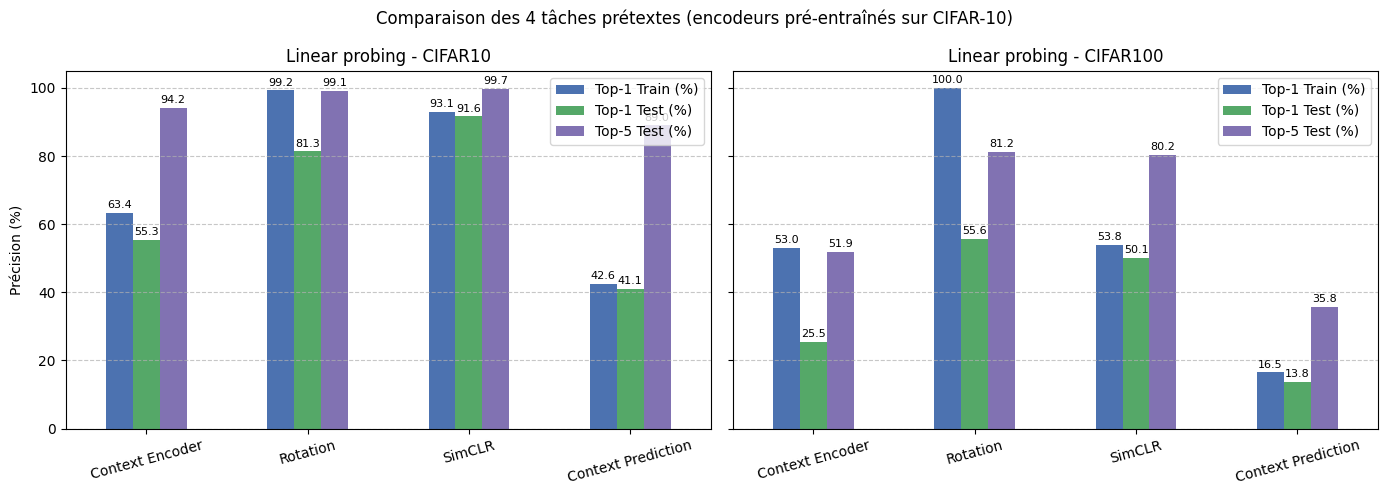

In [ ]:
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, TensorDataset
from deepul_helper.demos import load_model_and_data

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Paramètres :
SEED = 0
PRETRAIN_EPOCHS = 20      # Pré-entraînement de la tâche Context Prediction
PROBE_EPOCHS = 10         # Entraînement du classifieur linéaire
BATCH = 256
CP_IMG_SIZE = 128          # Taille requise pour extraire des patchs 32x32 (128 // 3), taille que l'encodeur de ContextPrediction attend
CKPT_CP = 'context_prediction_cifar10.pth'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Taille d'image attendue par chaque encodeur
IMG_SIZE = {'context_encoder': 128, 'rotation': 32, 'simclr': 32, 'context_prediction': CP_IMG_SIZE}
NICE = {'context_encoder': 'Context Encoder', 'rotation': 'Rotation', 'simclr': 'SimCLR', 'context_prediction': 'Context Prediction'}


def make_transform(size):
    return transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])


def get_dataset(name, train, size):
    """
    Charge le jeu de donnée : CIFAR10 ou CIFAR100
    """

    cls = torchvision.datasets.CIFAR10 if name == 'cifar10' else torchvision.datasets.CIFAR100
    return cls(root='./data', train=train, download=True, transform=make_transform(size))


# Pré-entraînement de ContextPrediction (sur CIFAR-10, sans labels)
def pretrain_context_prediction():
    """
    Cette fonction va s'occuper du pré-entraînement de Context Prediction sur CIFAR10.
    """

    model = ContextPrediction('cifar10', 10).to(device)
    if os.path.exists(CKPT_CP):
        model.load_state_dict(torch.load(CKPT_CP, map_location=device))
        print(f"Poids ContextPrediction rechargés depuis {CKPT_CP}")
        return model

    # Prépare les données d'entraînement
    loader = DataLoader(get_dataset('cifar10', True, CP_IMG_SIZE), batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)  # drop_last : BatchNorm1d
    opt = optim.Adam(model.parameters(), lr=1e-3)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=PRETRAIN_EPOCHS)

    print(f"Pré-entraînement de ContextPrediction ({PRETRAIN_EPOCHS} époques, labels CIFAR ignorés)...")
    for ep in range(PRETRAIN_EPOCHS):
        model.train()
        t0, tot_loss, tot_acc, n = time.time(), 0.0, 0.0, 0

        # On n'utilise pas les vrais labels car l'entraînement est en auto-supervisé.
        for images, _ in loader:
            images = images.to(device)
            metrics, _ = model(images)
            opt.zero_grad()
            metrics['Loss'].backward()
            opt.step()
            tot_loss += metrics['Loss'].item(); tot_acc += metrics['Accuracy'].item(); n += 1

        sched.step()
        print(f"  Époque {ep+1:2d}/{PRETRAIN_EPOCHS} - loss {tot_loss/n:.4f} | acc. position (tâche prétexte) {tot_acc/n:.1f}% - {time.time()-t0:.0f}s")

    torch.save(model.state_dict(), CKPT_CP)
    return model


# Évaluation par linear probing
@torch.no_grad()
def extract_features(model, loader):
    """
    L'encodeur est gelé donc on calcule une fois pour toutes les features.
    """

    model.eval()
    feats, labels = [], []
    for images, y in loader:
        f = model.encode(images.to(device))
        feats.append(torch.flatten(f, 1).cpu())
        labels.append(y)

    return torch.cat(feats), torch.cat(labels)


def topk_acc(logits, y):
    """
    Cette fonction calcule le nb de prédictions correctes pour les métriques du top 1 et 5.
    """

    top5 = logits.topk(5, dim=1).indices
    c1 = (top5[:, 0] == y).float().sum().item()
    c5 = (top5 == y[:, None]).any(dim=1).float().sum().item()
    return c1, c5


@torch.no_grad()
def eval_clf(clf, feats, labels, bs=1024):
    """
    Cette fonction évalue le classifieur linéaire sur les features qu'on a pré-calculées.
    """

    clf.eval()
    c1 = c5 = 0
    for i in range(0, len(feats), bs):
        out = clf(feats[i:i+bs].to(device))
        a, b = topk_acc(out, labels[i:i+bs].to(device))
        c1 += a; c5 += b
    return 100 * c1 / len(feats), 100 * c5 / len(feats)


def linear_probe(model, ds_name, n_classes, img_size):
    """
    On effectue le linear probing : on extrait les caractéristiques, on entraîne une couche linéaire simple
    et on évalue.
    """

    # Gel le modèle de base.
    for p in model.parameters():
        p.requires_grad = False
    model.eval()

    # Charge les données et extrait les caractéristiques.
    tr = DataLoader(get_dataset(ds_name, True, img_size), batch_size=BATCH, shuffle=False, num_workers=2)
    te = DataLoader(get_dataset(ds_name, False, img_size), batch_size=BATCH, shuffle=False, num_workers=2)
    ftr, ytr = extract_features(model, tr)
    fte, yte = extract_features(model, te)

    # Initialise le classifieur linéaire.
    model.n_classes = n_classes
    clf = model.construct_classifier().to(device)
    opt = optim.Adam(clf.parameters(), lr=1e-3)
    crit = nn.CrossEntropyLoss()

    # Entraîne le classifieur sur les caractéristiques pré-calculées.
    train_ds = TensorDataset(ftr, ytr)
    train_dl = DataLoader(train_ds, batch_size=512, shuffle=True, drop_last=True)
    for ep in range(PROBE_EPOCHS):
        clf.train()
        for f, y in train_dl:
            f, y = f.to(device), y.to(device)
            loss = crit(clf(f), y)
            opt.zero_grad(); loss.backward(); opt.step()

    # Evaluation finale
    tr1, tr5 = eval_clf(clf, ftr, ytr)
    te1, te5 = eval_clf(clf, fte, yte)

    return dict(train_top1=tr1, test_top1=te1, train_top5=tr5, test_top5=te5)


def get_model(name):
    """
    Récupère le modèle : Contexte Prediction, Context Encoder, Rotation ou SimCLR.
    """

    if name == 'context_prediction':
        return context_prediction_model               # Entraîné ici
    model, _, _, _ = load_model_and_data(name)       # Poids pré-entraînés avec CIFAR-10
    return model.to(device)


### Exécution ici :

# Pré-entraînemnet de Context Prediction
context_prediction_model = pretrain_context_prediction()

# Evalutaion par linear probing de toutes les tâches
DATASETS = {'cifar10': 10, 'cifar100': 100}
rows = []
for name in ['context_encoder', 'rotation', 'simclr', 'context_prediction']:
    model = get_model(name)
    for ds_name, n_classes in DATASETS.items():
        print(f"\n--- {NICE[name]} | {ds_name.upper()} (images {IMG_SIZE[name]}x{IMG_SIZE[name]}) ---")
        t0 = time.time()

        # Evaluation
        r = linear_probe(model, ds_name, n_classes, IMG_SIZE[name])
        print(f"Top-1 train {r['train_top1']:.2f}% | Top-1 test {r['test_top1']:.2f}% | "
              f"Top-5 test {r['test_top5']:.2f}% ({time.time()-t0:.0f}s)")

        # Tableau récapitulatif
        rows.append({'Dataset': ds_name.upper(), 'Modèle': NICE[name], **r})

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Sauvegarde les résultats
df = pd.DataFrame(rows).rename(columns={
    'train_top1': 'Top-1 Train (%)', 'test_top1': 'Top-1 Test (%)',
    'train_top5': 'Top-5 Train (%)', 'test_top5': 'Top-5 Test (%)'})
df.to_csv('resultats_consigne6.csv', index=False)

print("\nTableau récapitulatif :")
display(df.round(2))

# Graphiques
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, ds in zip(axes, ['CIFAR10', 'CIFAR100']):
    sub = df[df['Dataset'] == ds].set_index('Modèle')[['Top-1 Train (%)', 'Top-1 Test (%)', 'Top-5 Test (%)']]
    sub.plot(kind='bar', ax=ax, color=['#4C72B0', '#55A868', '#8172B2'], rot=15)
    ax.set_title(f'Linear probing - {ds}')
    ax.set_ylabel('Précision (%)'); ax.set_xlabel('')
    ax.set_ylim(0, 105); ax.grid(axis='y', linestyle='--', alpha=0.7)
    for c in ax.containers:
        ax.bar_label(c, fmt='%.1f', padding=2, fontsize=8)
plt.suptitle('Comparaison des 4 tâches prétextes (encodeurs pré-entraînés sur CIFAR-10)')
plt.tight_layout()
plt.savefig('comparaison_consigne6.png', dpi=150)
plt.show()

## Other Tasks
In addition to the above tasks, prior work has also investigated other self-superivsed tasks such as solving jigsaw puzzles [[4]](https://arxiv.org/abs/1603.09246), cycle-consistency [[5]](https://arxiv.org/abs/1903.07593), contrastive learning [[6]](https://arxiv.org/abs/1807.03748)[[7]](https://arxiv.org/abs/1905.09272)[[8]](https://arxiv.org/abs/1906.05849)[[9]](https://arxiv.org/abs/1911.05722), and patch prediction [[10]](https://arxiv.org/abs/1505.05192). See [here](https://github.com/jason718/awesome-self-supervised-learning) for a great resource on more self-supervised learning papers.

# Demo 4: Using Representations for Downstream Tasks

After pretraining a model on a self-supervised learning task, we can use it for other downstream tasks. In this demo, we use the pre-trained ResNet50 backbone from training SimCLR on a subset of ImageNet to learn a semantic segmentation model on Pascal VOC 2012. We use a simple U-Net [[11]](https://arxiv.org/abs/1505.04597) architecture with skip connections across feature maps between the SimCLR encoder and learned upsampling decoder. We do not fine-tune the SimCLR ResNet50 backbone, and only optimize the upsampling portion.

![](https://drive.google.com/uc?id=19dxxcwof0IA0jyv0VCl4rnZZf3ajA22s)

The training script can be found in `train_segmentation.py` [here](https://github.com/wilson1yan/cs294-158-ssl/blob/master/train_segmentation.py).

## Example Code

In [ ]:
# Code adapted from https://github.com/qubvel/segmentation_models.pytorch

import torch
import torch.nn as nn
import torch.nn.functional as F
from deepul_helper.resnet import NormReLU

class SegmentationModel(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, n_classes):
        super().__init__()

        decoder_channels = (512, 256, 128, 64, 32)
        encoder_channels = (2048, 1024, 512, 256, 64) # Starting from head (resnet 50)

        # Construct decoder blocks
        in_channels = [encoder_channels[0]] + list(decoder_channels[:-1])
        skip_channels = list(encoder_channels[1:]) + [0]
        out_channels = decoder_channels
        blocks = [
            DecoderBlock(in_ch, skip_ch, out_ch)
            for in_ch, skip_ch, out_ch in zip(in_channels, skip_channels, out_channels)
        ]
        self.dec_blocks = nn.ModuleList(blocks)

        # Segmentation head for output prediction
        self.seg_head = nn.Conv2d(decoder_channels[-1], n_classes, kernel_size=3, padding=1)

    def forward(self, features, targets):
        features = features[1:] # remove first skip with same spatial resolution
        features = features[::-1] # reverse channels to start from head of encoder

        skips = features[1:]
        x = features[0]
        for i, decoder_block in enumerate(self.dec_blocks):
            skip = skips[i] if i < len(skips) else None
            x = decoder_block(x, skip)

        logits = self.seg_head(x)
        loss = F.cross_entropy(logits, targets)

        return dict(Loss=loss), logits


class DecoderBlock(nn.Module):
    def __init__(
            self,
            in_channels,
            skip_channels,
            out_channels,
    ):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels + skip_channels, out_channels,
                      kernel_size=3, padding=1),
            NormReLU((out_channels, None, None)), # only care about channel dim for BN
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            NormReLU((out_channels, None, None))
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        x = self.conv1(x)
        x = self.conv2(x)
        return x

## Segmentation Results
Below, we show a random subset of segmentations from the trained model. Every set of 3 images consists of the original image, the labeled segmentation, and the predicted segmentation.

In [ ]:
from deepul_helper.demos import show_segmentation
show_segmentation()

# Demo 5: Avoiding Trivial Representations in Self-Supervised Tasks

When designing a self-supervised learning task, it is important to make sure that no trivial solutions exists. In general, a learned solution is trivial if the model is able to successfully complete its task by taking advantage of low-level features. As a result, it doesn't learn a good representation so downstream performance is bad.

For example, in the jigsaw [[4]](https://arxiv.org/abs/1603.09246) task, a model can "cheat" by just looking at the boundary textures of the jigsaw pieces, or following and matching straight lines across different pieces. These issues can generally be fixed by ranndom cropping, shifting, and spacially jittering.

We look at two other less obvious aspects of images that may reduce performance.

## Chromatic Aberration

Chromatic aberration occurs when the different focal lengths of light results in the light not meeting all at the same point.
![from wikipedia](https://drive.google.com/uc?id=1PYGoQWnH0aAeiE_8t4ef5WDcq1UIQQ5t)

A example of very apparent chromatic aberration is shown below, where the green and magenta colors are clearly offset with each other:

![](https://drive.google.com/uc?id=1M1B6kV6ddBwyJse3FQT8_XBTeqs5s5WL)

Chromatic aberration generally becomes a problem in patch-based self-supervised learning tasks that design, such as solving jigsaw puzzles, or predicintg the correct location of a patch in an image In this case, the model can take advantage of the low-level chromatic aberration features to get a strong idea of where the patch is located without understanding the actual context.

Below is a quick demo of chromatic aberration in more realistic images, and possible fixes. Note that in general, chromatic aberration is fairly hard to spot with the naked eye, but deep learning models are still able to use it to their advantage.

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# You can see some chromatic aberration in the purple fringes around the branches

image = Image.open('sample_images/chrom_ab_demo.png')
plt.figure()
plt.axis('off')
plt.imshow(image)
plt.show()

Chromatic aberration is generally fixed through conversion to grayscale, or color dropping. Color dropping works by dropping 2 of the color channels and replacing them with random noise uniform or Gaussian noise.

In [ ]:
import numpy as np

# Color Dropping
# We will drop all channels except R
image_cpy = image.copy()
pixels = image_cpy.load()

arr = np.array(image_cpy)
std_R = np.std(arr[:, :, 0])
mean_G, mean_B = np.mean(arr[:, :, 1]), np.mean(arr[:, :, 2])

for i in range(image.size[0]):
  for j in range(image.size[1]):
    p = pixels[i, j] # (R, G, B, A)
    R, A = p[0], p[3]
    G = int(np.random.randn() * std_R + mean_G)
    B = int(np.random.randn() * std_R + mean_B)
    pixels[i, j] = (R, G, p[2], p[3])

plt.figure()
plt.title('Color Dropping')
plt.axis('off')
plt.imshow(image_cpy)
plt.show()

# Grayscale
image_cpy2 = image.copy()
pixels2 = image_cpy2.load()

for i in range(image.size[0]):
  for j in range(image.size[1]):
    p = pixels[i, j]
    G = int(0.3 * p[0] + 0.59 * p[1] + 0.11 * p[2])
    pixels2[i, j] = (G, G, G, 255)

plt.figure()
plt.title('Grayscale')
plt.axis('off')
plt.imshow(image_cpy2)
plt.show()

## Color Intensity Histograms

In the SimCLR paper, the authors show that the histogram of color intensities of different patches within the same image have very similar histograms, which may degrade training by encouraging models to look at low-level (pixel intensity) features to solve self-supervised tasks that involve matching positive patches of the same image.

Below, we run a similar demo to what was demonstrated in the paper

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open('sample_images/n01537544_19414.JPEG')
plt.figure()
plt.title('Original Image')
plt.axis('off')
plt.imshow(image)
plt.show()

In [ ]:
import numpy as np
arr = np.array(image)
H, W, _ = arr.shape

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
  r = np.random.randint(0, H - 128)
  c = np.random.randint(0, W - 128)
  patch = arr[r:r+128, c:c+128]

  axs[i].set_title(f'Patch {i}')
  axs[i].hist(patch.reshape(-1), bins=50)
plt.show()

Now we apply color jittering to mitigate this effect

In [ ]:
from torchvision import transforms

color_jitter = transforms.ColorJitter(0.3, 0.3, 0.3, 0.3)
jitter_img = color_jitter(image)

image = Image.open('sample_images/n01537544_19414.JPEG')
plt.figure()
plt.title('Color Jittered Image')
plt.axis('off')
plt.imshow(jitter_img)
plt.show()

In [ ]:
arr = np.array(image)
H, W, _ = arr.shape

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
  r = np.random.randint(0, H - 128)
  c = np.random.randint(0, W - 128)
  patch = arr[r:r+128, c:c+128]

  axs[i].set_title(f'Patch {i}')
  axs[i].hist(patch.reshape(-1), bins=50)
plt.show()